# Validar la agregación y los componentes de estrés

**Pregunta:** Cuando se ejecutan las baterías de pruebas del motor sobre la agregación de capital y los satélites de estrés de
Banco Andino, ¿qué componentes resisten y cuáles fallan, y qué significa cada falla para el número de capital?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 06 de este tema (la agregación, los satélites y el plan de capital)
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook puedes:

- ejecutar las siete pruebas de agregación del motor sobre el capital de Banco Andino y leer cada luz y su estadístico, con la
  regla que la fija;
- ejecutar la prueba de acuerdo de Monte Carlo en el único caso donde la fórmula de la raíz cuadrada es exacta, y plantar una
  discrepancia de horizonte para que el motor la detecte;
- retroproyectar los cinco satélites fuera de tiempo, leer por qué todos están en rojo, y ver al motor rechazar una ventana de
  ajuste que se filtra en el episodio;
- ejecutar la prueba de signos, la de severidad de escenarios y la regla de abajo-arriba, y decir qué prueba y qué no prueba cada
  una;
- leer toda la batería de una vez y decir qué significa para la pérdida de crédito estresada del caso.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un notebook nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del notebook que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el notebook e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importaciones, versiones y lector de los documentos versionados (tres carpetas bajo la raíz del repositorio)
import importlib.metadata as md
import json
from collections import Counter
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import simple
from riskvalidation.validation import aggregation as agg_tests
from riskvalidation.validation import portfolio as port_tests
from riskvalidation.validation import stress as stress_tests

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
DERIVED = Path("../../..").resolve() / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Este notebook lee las **filas de prueba** de **C18** (Banco Andino) y los insumos que necesitan.

- **Propietario y licencia:** los documentos los escribe el flujo sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este notebook son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este notebook, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/baseline.json` (las filas de prueba de agregación y de estrés, las marginales, la banda, el bloque de retroproyección, las filas de severidad), `t-copula-baseline.json` (la banda con estrés de correlación y las dos pruebas de agregación que el escenario base no lleva), `fed-2026-severely-adverse.json`, `eba-2025-adverse.json` y `ngfs-delayed-transition.json` (la severidad de cada escenario) y `models-banco-andino.json` (los coeficientes de los satélites). Una **fila de prueba** es una llamada de prueba del motor guardada como diccionario: `test_id`, `model_id`, `segment`, `statistic`, `metric`, `light` y `extras`.
- **Qué son las luces.** Las pruebas de agregación y de estrés son **umbrales internos de Contraste**, declarados como tales, no umbrales regulatorios ni pruebas de hipótesis: cada función declara su regla en su docstring y registra sus parámetros en `extras["thresholds"]`. El motor no declara cumplimiento.

In [2]:
# El documento base y sus filas de prueba, el segundo documento de agregación, las variantes de escenario y los
# modelos
baseline_doc = read_json("C18/baseline.json")
baseline = baseline_doc["outputs"]
agg = baseline["aggregation"]
second = read_json("C18/t-copula-baseline.json")
models = read_json("C18/models-banco-andino.json")["fit"]
names = ("eba-2025-adverse", "fed-2026-severely-adverse", "ngfs-delayed-transition")
variants = {name: read_json(f"C18/{name}.json") for name in names}
baked = baseline_doc["provenance"]["riskvalidation_version"]
print("filas de prueba horneadas con riskvalidation, instalada", baked, rv.__version__)
R = np.array(agg["correlation"]["matrix"])
ec = np.array([m["ec_clp_m"] for m in agg["marginals"]])
band = {(r["method"], r["nu"]): r["capital_clp_m"] for r in agg["band"]}
COLOUR = {"green": "#3a8f5c", "amber": "#d9a21b", "red": "#b23a48", "not_evaluated": "#9aa5b1", "error": "#6c757d"}
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada",
         "error": "error"}
TEST = {"aggregation.simple_sum_and_variance_covariance": "suma simple y ancla de raíz cuadrada",
        "aggregation.copula_choice_sensitivity": "elección de cópula",
        "aggregation.worst_case_bracket": "cota del peor caso",
        "aggregation.correlation_stress": "estrés de correlación",
        "aggregation.diversification_sign": "signo de la diversificación",
        "aggregation.horizon_confidence_consistency": "horizonte y nivel",
        "portfolio.euler_additivity": "aditividad de Euler",
        "aggregation.elliptical_mc_agreement": "acuerdo de Monte Carlo",
        "aggregation.rosenberg_schuermann_reference": "referencia publicada",
        "stress.satellite_backcast": "retroproyección de satélites",
        "stress.sensitivity_monotonicity": "signo de los coeficientes",
        "stress.scenario_severity": "severidad del escenario",
        "stress.static_balance_sheet_rules": "balance estático",
        "stress.bottom_up_vs_top_down": "abajo-arriba contra arriba-abajo",
        "stress.reverse_solution_check": "solución del estrés inverso"}

filas de prueba horneadas con riskvalidation, instalada 1.0.1 1.0.1


## Método

### Paso 1: las pruebas de agregación

El dossier 05 (G.5) lista qué verificar en un modelo de capital económico: comparar la agregación con la suma simple y la fórmula de la raíz cuadrada, informar la sensibilidad a la elección de cópula, informar las cotas de peor caso, estresar la correlación entre riesgos, comprobar que la asignación suma y el signo de cada beneficio de diversificación, y comprobar que se aplican un horizonte y un nivel de confianza. El motor tiene una prueba para cada una, y las reglas son estas (todo umbral es propio de Contraste):

| Prueba | Regla de la luz |
|---|---|
| `simple_sum_and_variance_covariance` | roja si el agregado supera la suma simple; ámbar si está a más de 10 por ciento del ancla de raíz cuadrada; verde en otro caso |
| `copula_choice_sensitivity` | verde hasta 5 por ciento entre la gaussiana y la mayor diferencia t, ámbar hasta 15 por ciento, roja sobre eso |
| `worst_case_bracket` | roja si alguna fila de la banda queda fuera de la cota inferior y el peor caso |
| `correlation_stress` | roja si el capital baja cuando sube una correlación; ámbar si sube más de 10 por ciento |
| `diversification_sign` | roja si alguna fila diversificada supera la suma simple |
| `horizon_confidence_consistency` | roja si alguna marginal está en otro horizonte o nivel que un año y 99,9 por ciento |
| `euler_additivity` | verde si las contribuciones suman el total dentro de $10^{-6}$ |

La celda siguiente recalcula las siete pruebas a partir de los números versionados (los capitales, la banda, la banda con
estrés y la asignación de Euler) con las funciones de prueba del motor, y dibuja cada prueba en la luz que obtiene, con su
estadístico al lado.

In [3]:
# Las entradas de las siete pruebas de agregación, tomadas de los números versionados
gaussian, lower, worst = band[("gaussian-copula", None)], band[("lower-bound", None)], band[("worst-case", None)]
t_caps = [(nu, band[("t-copula", nu)]) for nu in agg["nu_set"]["values"]]
between = [v for (method, nu), v in band.items() if method not in ("lower-bound", "worst-case")]
stress_band = second["outputs"]["correlation_stress"]["aggregation"]["band"]
stressed = {(r["method"], r["nu"]): r["capital_clp_m"] for r in stress_band}
kinds = ("variance-covariance", "gaussian-copula", "t-copula")
diversified = [r["diversification_factor"] for r in agg["band"] if r["method"] in kinds]
contributions = np.array([row["contribution_clp_m"] for row in agg["euler"]["allocation"]])
es_total = agg["euler"]["es_total_clp_m"]

Las entradas están listas, así que la celda siguiente ejecuta las siete pruebas y las dibuja.

suma simple y ancla de raíz cuadrada             verde          0.9316
elección de cópula                               ámbar          0.1228
cota del peor caso                               verde     704814.0561
estrés de correlación                            ámbar          0.1211
signo de la diversificación                      verde          0.8394
horizonte y nivel                                verde          0.0000
aditividad de Euler                              verde     709389.8923
dispersión de cópula y estrés de correlación, porcentaje 12.3 12.1


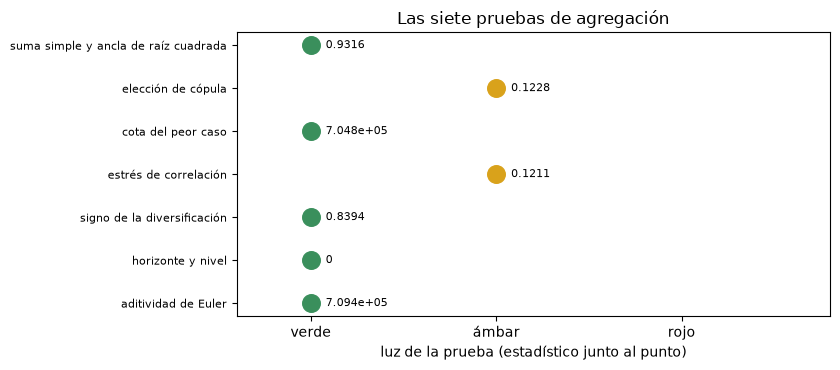

In [4]:
# Ejecutar las siete pruebas de agregación y dibujar cada una en la luz que obtiene
results = {
    "aggregation.simple_sum_and_variance_covariance": agg_tests.simple_sum_and_variance_covariance(ec, R, gaussian),
    "aggregation.copula_choice_sensitivity": agg_tests.copula_choice_sensitivity(gaussian, t_caps),
    "aggregation.worst_case_bracket": agg_tests.worst_case_bracket(lower, between, worst),
    "aggregation.correlation_stress": agg_tests.correlation_stress(gaussian, stressed[("gaussian-copula", None)]),
    "aggregation.diversification_sign": agg_tests.diversification_sign(diversified),
    "aggregation.horizon_confidence_consistency": agg_tests.horizon_confidence_consistency([1] * 4, [0.999] * 4),
    "portfolio.euler_additivity": port_tests.euler_additivity(contributions, es_total, 1e-6),
}
order = ["green", "amber", "red"]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for k, (test_id, result) in enumerate(results.items()):
    level = order.index(result.light.value)
    ax.scatter([level], [-k], s=160, color=COLOUR[result.light.value])
    ax.text(level + 0.08, -k, f"{result.statistic:.4g}", va="center", fontsize=8)
    print(f"{TEST[test_id]:48s} {LIGHT[result.light.value]:6s} {result.statistic:14.4f}")
ax.set_yticks([-k for k in range(len(results))])
ax.set_yticklabels([TEST[t] for t in results], fontsize=8)
ax.set_xticks(range(3))
ax.set_xticklabels([LIGHT[c] for c in order])
ax.set_xlim(-0.4, 2.8)
ax.set_xlabel("luz de la prueba (estadístico junto al punto)")
ax.set_title("Las siete pruebas de agregación")
spread = results["aggregation.copula_choice_sensitivity"].statistic
stress = results["aggregation.correlation_stress"].statistic
print("dispersión de cópula y estrés de correlación, porcentaje", round(spread * 100, 1), round(stress * 100, 1))
fig.tight_layout()
plt.show()

Cinco pruebas están en verde y dos en ámbar, y las dos ámbar dicen algo. La elección de cópula mueve el capital hasta 12,3
por ciento, la cópula t con cuatro grados de libertad contra la gaussiana, sobre el umbral de 5 por ciento: la respuesta
depende de una elección de modelado que ningún dato del caso puede resolver. El estrés mercado-crédito a 0,8 eleva la fila
gaussiana 12,1 por ciento, sobre su umbral de 10 por ciento: la respuesta depende de una correlación que es una convención.
Ninguna es una falla del modelo, cada una es una sensibilidad que el lector debe ver, y por eso la banda se muestra entera. El
agregado es 93,2 por ciento del ancla de la raíz cuadrada y la cota del peor caso se cumple.

**La prueba de concordancia de Monte Carlo.** En el único caso en que la fórmula de raíz cuadrada es exacta, marginales normales con cópula gaussiana, una simulación debe concordar con ella. `elliptical_mc_agreement(mc_capital, mc_se, vc_capital, z)` comprueba que el capital simulado esté a menos de $z = 3$ errores estándar de la fórmula: es la prueba del simulador mismo.

La celda siguiente ejecuta esa simulación como lo hace el flujo de generación, con marginales normales que tienen los
capitales versionados, un millón de simulaciones y la semilla 49 (la del caso, 42, más 7), y dibuja el capital simulado con tres
errores estándar alrededor frente a la fórmula. También ejecuta la verificación de horizonte y nivel sobre una discrepancia
plantada, una marginal con horizonte de diez días.

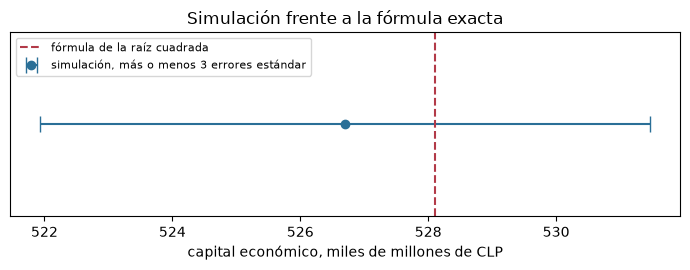

capital simulado y error estándar 526698.8 1587.1
estadístico, en errores estándar, y luz -0.8868 verde
marginal plantada a diez días rojo ['irrbb']


In [5]:
# La prueba de acuerdo de Monte Carlo con marginales normales y cópula gaussiana, y la verificación de horizonte
# ante una discrepancia
LEVEL = 0.999
z_level = stats.norm.ppf(LEVEL)
normal_ppfs = [partial(stats.norm.ppf, scale=capital / z_level) for capital in ec]
simulation = cop.copula_aggregate(normal_ppfs, R, "gaussian", None, 0.0, LEVEL, 1_000_000, 49, 100_000)
vc_total = simple.variance_covariance(ec, R)
agreement = agg_tests.elliptical_mc_agreement(simulation.ec, simulation.var_se, vc_total)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.errorbar([simulation.ec / 1e3], [0], xerr=[3 * simulation.var_se / 1e3], fmt="o", color="#2a6f97", capsize=6,
            label="simulación, más o menos 3 errores estándar")
ax.axvline(vc_total / 1e3, color="#b23a48", linestyle="--", label="fórmula de la raíz cuadrada")
ax.set_yticks([])
ax.set_xlabel("capital económico, miles de millones de CLP")
ax.set_title("Simulación frente a la fórmula exacta")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()
print("capital simulado y error estándar", round(simulation.ec, 1), round(simulation.var_se, 1))
print("estadístico, en errores estándar, y luz", round(agreement.statistic, 4), LIGHT[agreement.light.value])
planted = agg_tests.horizon_confidence_consistency([1.0, 1.0, 10 / 250, 1.0], [0.999] * 4)
offending = [agg["marginals"][i]["risk"] for i in planted.extras["offending_indices"]]
print("marginal plantada a diez días", LIGHT[planted.light.value], offending)

El capital simulado es 526.699 millones con un error estándar de 1.587, que es 0,89 errores estándar bajo el ancla de la raíz
cuadrada de 528.106 millones, bien dentro del umbral de tres. Es la prueba del simulador mismo, en el único caso en que la
fórmula es exacta, y la figura muestra la fórmula dentro de la barra de error. La marginal plantada a diez días pone en rojo la
verificación de horizonte y nivel y nombra la tercera marginal, el riesgo de tasa de interés. Una prueba que nunca falla no ha
demostrado que funcione, y por eso aquí se planta una discrepancia.

### Paso 2: la retroproyección de los satélites

Un satélite se valida **fuera de tiempo**: se ajusta con datos que terminan antes de un episodio, se corre a través del episodio con las variables macro **realizadas** y se comparan las tasas de pérdida predichas y realizadas (dossier 05, H.7). El caso ajusta sobre 1985 a 2019 y retroproyecta 2020 T1 a 2025 T4, que contiene el choque de la pandemia. `satellite_backcast(predicted, realised, quarters, fit_end, peak_amber, peak_red, timing_quarters)` compara los máximos:

- **estadístico** la RMSE de lo predicho contra lo realizado; **métrica** el error de tiempo en trimestres (trimestre del máximo predicho menos trimestre del máximo realizado);
- luz **verde** cuando el máximo predicho está a menos de 35 por ciento del máximo realizado en tamaño y a menos de 2 trimestres en tiempo, **ámbar** a menos de 60 por ciento, **roja** en otro caso;
- la luz **`error`** cuando la ventana de ajuste no es estrictamente anterior al episodio: una retroproyección sobre datos con que se ajustó es filtración, y la prueba se niega a correr.

La celda siguiente recalcula la prueba para los cinco tipos de crédito a partir de los trimestres predichos y realizados
versionados, dibuja las tasas predichas contra las realizadas e imprime la razón de picos, el tiempo y el RMSE. Luego planta
una filtración, un ajuste que termina en 2020 T2.

comercial e industrial     razón de picos    4.55 tiempo    0 RMSE 0.0055 rojo
inmobiliario comercial     razón de picos   13.14 tiempo  -14 RMSE 0.0079 rojo
hipotecas residenciales    razón de picos  252.13 tiempo  -12 RMSE 0.0068 rojo
tarjetas de crédito        razón de picos    4.30 tiempo  -17 RMSE 0.0371 rojo
otro consumo               razón de picos    2.09 tiempo  -21 RMSE 0.0051 rojo


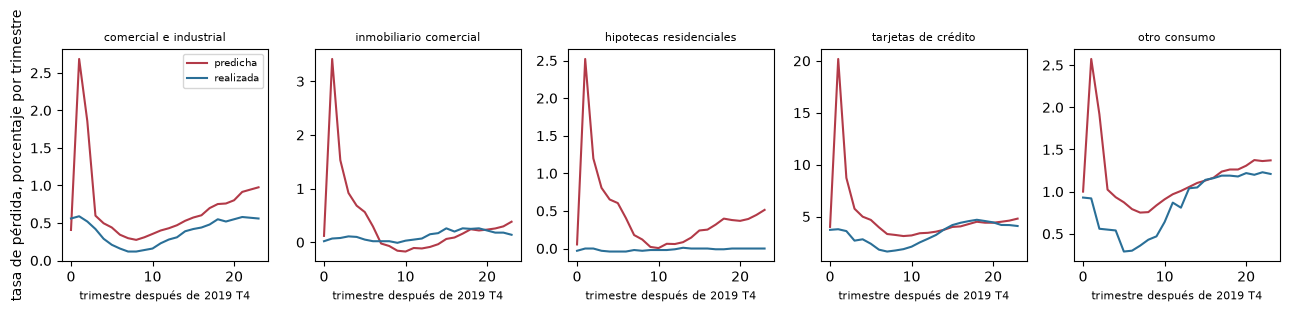

ventana de ajuste que termina en 2020-06-30 error


In [6]:
# La prueba de retroproyección de cada tipo de crédito desde los trimestres versionados, y una ventana de ajuste
# que se filtra
LOAN = {"commercial-industrial": "comercial e industrial",
        "commercial-real-estate": "inmobiliario comercial",
        "residential": "hipotecas residenciales", "credit-cards": "tarjetas de crédito",
        "other-consumer": "otro consumo"}
backcast = {b["fed_loan_type"]: b for b in baseline["backcast"]["per_loan_type"]}
fig, axes = plt.subplots(1, 5, figsize=(13, 3), sharex=True)
for ax, (loan_type, block) in zip(axes, backcast.items()):
    predicted = [q["predicted"] for q in block["quarters"]]
    realised = [q["realised"] for q in block["quarters"]]
    ends = [q["quarter_end"] for q in block["quarters"]]
    result = stress_tests.satellite_backcast(predicted, realised, ends, block["fit_window"]["end"])
    ax.plot(np.array(predicted) * 100, color="#b23a48", label="predicha")
    ax.plot(np.array(realised) * 100, color="#2a6f97", label="realizada")
    ax.set_title(LOAN[loan_type], fontsize=8)
    ax.set_xlabel("trimestre después de 2019 T4", fontsize=8)
    print(f"{LOAN[loan_type]:26s} razón de picos {result.extras['peak_ratio']:7.2f} tiempo {result.metric:4.0f}"
          f" RMSE {result.statistic:.4f} {LIGHT[result.light.value]}")
axes[0].set_ylabel("tasa de pérdida, porcentaje por trimestre")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()
block = backcast["credit-cards"]
quarters = [q["quarter_end"] for q in block["quarters"]]
leak = stress_tests.satellite_backcast([q["predicted"] for q in block["quarters"]],
                                       [q["realised"] for q in block["quarters"]], quarters, "2020-06-30")
print("ventana de ajuste que termina en 2020-06-30", LIGHT[leak.light.value])

Los cinco satélites están en rojo. Todos predicen su mayor tasa de pérdida en 2020 T2, el trimestre del choque, desde 2,09
veces el pico realizado en otro consumo hasta 252 veces en hipotecas residenciales. Solo el comercial e industrial alcanzó ahí
su pico, y los otros cuatro realizaron sus picos de 12 a 21 trimestres después: los satélites reaccionan con fuerza a las
variables macro realizadas de 2020, y los castigos realizados no los siguieron. Un validador lee esto como un hallazgo sobre
los números estresados del caso, porque la pérdida de crédito de un escenario severo se apoya en satélites que habrían
sobrestimado la única recesión que cayó dentro de la retroproyección. La ventana de ajuste que termina en 2020 T2 se rechaza
como error.

### Paso 3: signos, severidad, las reglas estáticas y abajo-arriba frente a arriba-abajo

**Signos.** `sensitivity_monotonicity(estimates, expected_signs)` cuenta los coeficientes con el signo equivocado respecto del signo declarado **antes** del ajuste (el crecimiento baja la tasa de pérdida: negativo; el desempleo la sube: positivo; el término autorregresivo: positivo), de modo que la pérdida proyectada sea monótona en la severidad de la trayectoria. Es roja cuando algún coeficiente está equivocado.

**Severidad.** `scenario_severity(path_peak, history_peak, is_stress, minimum)` compara la desviación máxima de una variable del escenario con la misma desviación en la crisis financiera global (2008 T1 a 2009 T4): la razón debe ser al menos 0,75, verde si es así y **ámbar** bajo eso (sin rojo: un estrés suave es un hallazgo sobre el escenario, no una falla); el escenario base no es una trayectoria de estrés y es `not_evaluated`.

**Reglas estáticas.** `static_balance_sheet_rules` se corrió en el notebook 05.

**Abajo-arriba frente a arriba-abajo.** `bottom_up_vs_top_down(bottom_up, top_down, amber, red)` compara la pérdida con estrés del banco con la de un modelo **retador**: verde dentro de 25 por ciento, ámbar dentro de 50, roja más allá. El caso no hornea un retador arriba-abajo, así que la regla se muestra sobre el único par de totales que dan los documentos y que difieren solo por escenario, la pérdida a tres años de los escenarios adversos de la Reserva Federal y de la EBA, como demostración de la regla y no como comparación con un retador.

La celda siguiente ejecuta la prueba de signos sobre los 30 coeficientes y dibuja cada estimación por su signo declarado, de
modo que una barra negativa es un coeficiente con el signo equivocado, luego ejecuta la prueba de severidad sobre cada variable
de escenario y dibuja la razón respecto de la crisis contra el umbral de 0,75, y aplica la regla de abajo-arriba a las dos
pérdidas adversas.

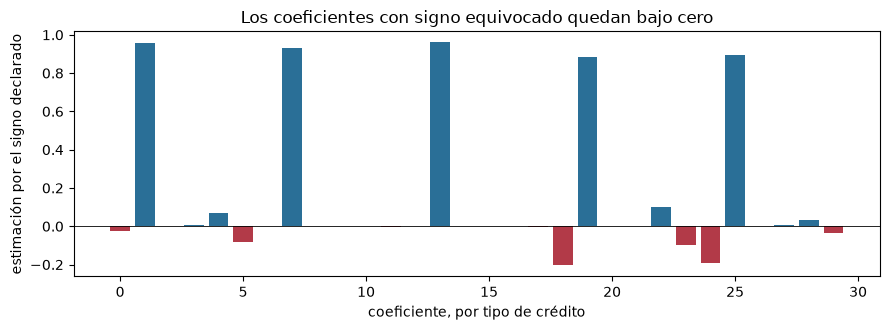

coeficientes probados, signo equivocado, luz
30 6 rojo
  comercial e industrial: real_gdp_growth_lag0         +0.00069
  inmobiliario comercial: real_gdp_growth_lag1         +0.00005
  hipotecas residenciales: real_gdp_growth_lag0        +0.00005
  hipotecas residenciales: real_gdp_growth_lag1        +0.00006
  tarjetas de crédito: real_gdp_growth_lag0            +0.00038
  tarjetas de crédito: real_gdp_growth_lag1            +0.00057


In [7]:
# La prueba de signos sobre los 30 coeficientes de los satélites: cada estimación por el signo declarado antes
# del ajuste
estimates, signs, labels = [], [], []
for model in models["satellites"]:
    for coefficient in model["coefficients"]:
        estimates.append(coefficient["estimate"])
        signs.append(coefficient["expected_sign"])
        labels.append(f'{LOAN[model["fed_loan_type"]]}: {coefficient["name"]}')
sign_test = stress_tests.sensitivity_monotonicity(estimates, signs)
direction = np.array([-1.0 if s == "negative" else 1.0 for s in signs])
signed = np.array(estimates) * direction
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(range(len(signed)), signed, color=["#b23a48" if v < 0 else "#2a6f97" for v in signed])
ax.axhline(0, color="black", linewidth=0.6)
ax.set_xlabel("coeficiente, por tipo de crédito")
ax.set_ylabel("estimación por el signo declarado")
ax.set_title("Los coeficientes con signo equivocado quedan bajo cero")
fig.tight_layout()
plt.show()
print("coeficientes probados, signo equivocado, luz")
print(sign_test.n, int(sign_test.statistic), LIGHT[sign_test.light.value])
for index in sign_test.extras["offending_indices"]:
    print(f"  {labels[index]:52s} {estimates[index]:+.5f}")

Seis de los 30 coeficientes tienen el signo equivocado, y los seis son coeficientes del crecimiento del PIB: comercial e
industrial (rezago 0), inmobiliario comercial (rezago 1), residencial (rezagos 0 y 1) y tarjetas de crédito (rezagos 0 y 1)
resultan ligeramente positivos donde se declaró un signo negativo antes del ajuste. Son minúsculos, entre 0,00005 y 0,0007, al
lado de los coeficientes del desempleo, que cargan la proyección, así que el efecto práctico es pequeño, pero la prueba es roja
por su regla. La regla existe para que la pérdida proyectada de un satélite sea monótona en la severidad de la trayectoria, y
seis violaciones pequeñas bastan para decir que no está garantizada.

Fed base                 unemployment_rate   0.000 no evaluada
Fed base                 real_gdp_growth     0.000 no evaluada
Fed base                 prime_rate          0.000 no evaluada
EBA adverso              real_gdp_growth     0.711 ámbar
EBA adverso              unemployment_rate   1.170 verde
EBA adverso              treasury_10y        1.128 verde
Fed severamente adverso  unemployment_rate   1.078 verde
Fed severamente adverso  real_gdp_growth     0.582 ámbar
Fed severamente adverso  prime_rate          0.929 verde
NGFS                     unemployment_rate   0.112 ámbar
NGFS                     prime_rate          0.144 ámbar
NGFS                     treasury_10y        0.112 ámbar
NGFS                     real_gdp_growth     0.036 ámbar


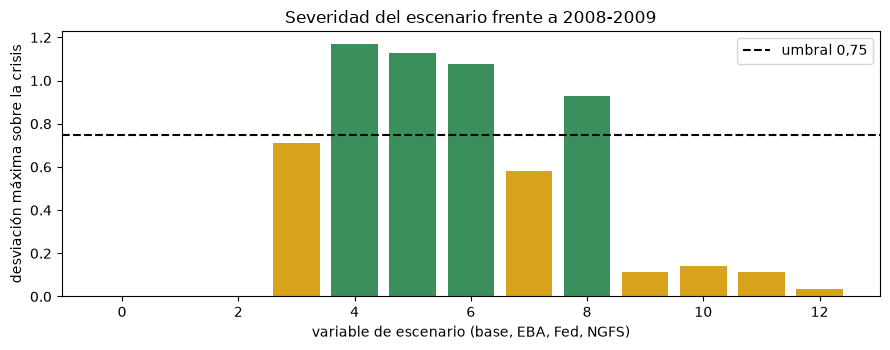

pérdida EBA sobre pérdida Fed, menos uno 0.0727 verde


In [8]:
# La severidad de cada variable de escenario frente a la crisis financiera global, y la regla de abajo-arriba
# sobre dos pérdidas
SCENARIO = {"baseline": "Fed base", "eba-2025-adverse": "EBA adverso",
            "fed-2026-severely-adverse": "Fed severamente adverso", "ngfs-delayed-transition": "NGFS"}
fig, ax = plt.subplots(figsize=(9, 3.6))
position = 0
for name, document in {"baseline": baseline_doc, **variants}.items():
    for severity in document["outputs"]["severity"]["rows"]:
        args = (severity["path_peak_deviation"], severity["history_peak_deviation"], severity["is_stress"])
        result = stress_tests.scenario_severity(*args)
        ratio = 0.0 if result.statistic != result.statistic else result.statistic
        ax.bar(position, ratio, color=COLOUR[result.light.value])
        position += 1
        print(f"{SCENARIO[name]:24s} {severity['maps_to_regressor']:18s} {ratio:6.3f} {LIGHT[result.light.value]}")
ax.axhline(0.75, color="black", linestyle="--", label="umbral 0,75")
ax.set_xlabel("variable de escenario (base, EBA, Fed, NGFS)")
ax.set_ylabel("desviación máxima sobre la crisis")
ax.set_title("Severidad del escenario frente a 2008-2009")
ax.legend()
fig.tight_layout()
plt.show()
totals = {name: sum(r["total"] for r in d["outputs"]["losses"]["scenario_losses"]) for name, d in variants.items()}
demo = stress_tests.bottom_up_vs_top_down(totals["eba-2025-adverse"], totals["fed-2026-severely-adverse"])
print("pérdida EBA sobre pérdida Fed, menos uno", round(demo.statistic, 4), LIGHT[demo.light.value])

La severidad es mixta. El escenario severamente adverso de la Reserva Federal pasa en desempleo (1,078 veces la crisis) y en
tasa de política (0,929) y es ámbar en crecimiento del PIB, con 0,582. El escenario adverso de la EBA es ámbar en crecimiento
(0,711) y verde en lo demás. Todas las variables de la NGFS son ámbar, entre 0,04 y 0,14, porque el choque de transición
tardía es un choque de política climática mucho más suave en términos macro que la crisis, y las barras de la base son cero
porque la base no es una trayectoria de estrés y no se evalúa. La regla de abajo-arriba se muestra y no se corre contra un
retador: la pérdida a tres años del escenario adverso de la EBA es 7,3 por ciento mayor que la del severo de la Reserva
Federal, verde frente a los umbrales de 25 y 50 por ciento.

## Resultados

La celda siguiente cuenta todas las filas de prueba versionadas del caso por prueba y luz, las 17 filas del documento base y
las dos pruebas de agregación que solo trae el segundo documento, de modo que toda la batería sea visible de una vez.

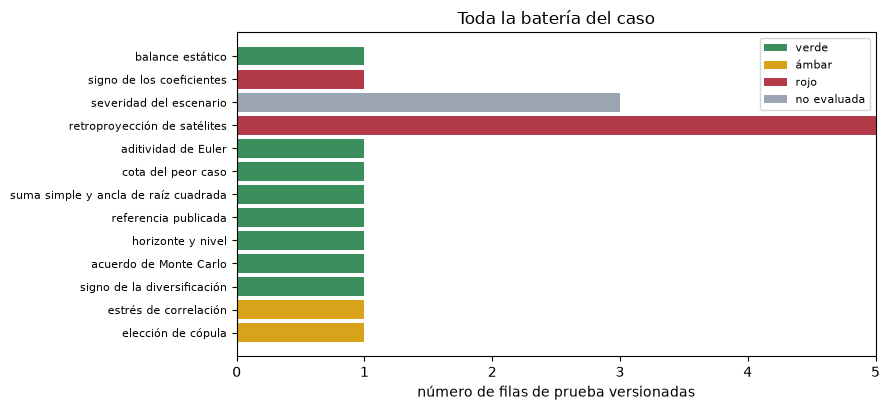

filas versionadas 19 {'green': 8, 'amber': 2, 'red': 6, 'not_evaluated': 3}


In [9]:
# Contar las filas de prueba versionadas de C18 por prueba y luz entre el documento base y el segundo
extra = ("aggregation.elliptical_mc_agreement", "aggregation.rosenberg_schuermann_reference")
rows = baseline_doc["tests"] + [t for t in second["tests"] if t["test_id"] in extra]
ids = sorted({t["test_id"] for t in rows})
fig, ax = plt.subplots(figsize=(9, 4.2))
left = np.zeros(len(ids))
for light in ("green", "amber", "red", "not_evaluated"):
    counts = np.array([sum(1 for t in rows if t["test_id"] == i and t["light"] == light) for i in ids])
    ax.barh(range(len(ids)), counts, left=left, color=COLOUR[light], label=LIGHT[light])
    left += counts
ax.set_yticks(range(len(ids)))
ax.set_yticklabels([TEST.get(i, i) for i in ids], fontsize=8)
ax.set_xlabel("número de filas de prueba versionadas")
ax.set_title("Toda la batería del caso")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("filas versionadas", len(rows), dict(Counter(t["light"] for t in rows)))

Las barras rojas están todas en la capa de estrés: la retroproyección de los cinco satélites y la prueba de signos, mientras
las pruebas de agregación son verdes o ámbar. De 19 filas versionadas, 8 son verdes, 2 ámbar, 6 rojas y 3 no evaluadas, y la
lectura es la misma que la de las pruebas recalculadas arriba. La agregación se puede defender mostrando sus sensibilidades; la
pérdida de crédito estresada no se puede defender más que como una lectura de sus satélites, que fallan su propia validación.

**Respuesta:** la agregación resiste y los satélites de estrés no. Las siete pruebas de agregación dan cinco luces verdes y dos
ámbar, la elección de cópula (una dispersión de 12,3 por ciento frente a un umbral de 5 por ciento) y el estrés de correlación
(12,1 por ciento frente a 10), ambas sensibilidades que la banda existe para mostrar, y la prueba de acuerdo de Monte Carlo es
verde a 0,89 errores estándar de la fórmula exacta. La capa de estrés falla: los cinco satélites están en rojo en la
retroproyección, con picos predichos de 2,09 a 252,13 veces los realizados, y seis de 30 coeficientes tienen el signo
equivocado. En las 19 filas de prueba versionadas el recuento es 8 verdes, 2 ámbar, 6 rojas y 3 no evaluadas, de modo que la
pérdida de crédito estresada del notebook 05 se apoya en satélites que la propia batería del motor marca en rojo.

Lo que este notebook no muestra: los umbrales son los internos de Contraste, así que una luz es una lectura de esa política y
no un veredicto regulatorio; el caso no tiene modelo retador, así que abajo-arriba contra arriba-abajo se demostró y no se
realizó; y las luces dicen que los satélites son débiles, no qué daría un modelo mejor.

## Resumen

- El motor tiene una prueba para cada verificación del dossier 05: siete para la agregación (más la concordancia de Monte Carlo y la referencia publicada) y seis para el estrés, cada una con una regla declarada y umbrales que son de Contraste, no del regulador.
- Recalculadas desde los números versionados, toda prueba de agregación y las pruebas de retroproyección, signo y severidad dan la luz y el estadístico versionados; la prueba de concordancia de Monte Carlo es verde en una simulación nueva.
- Las dos luces ámbar de agregación son sensibilidades (la elección de cópula y el estrés de correlación) que la banda existe para mostrar; las luces rojas son sobre los **satélites**: los cinco fallan su retroproyección y seis coeficientes tienen el signo equivocado.
- Las pruebas rechazan lo que deben: un horizonte discrepante es rojo, una ventana de ajuste que se filtra en el episodio es `error`, y un escenario más suave que la crisis financiera global es ámbar.
- La consecuencia no es que el caso esté equivocado, sino que su pérdida de crédito con estrés descansa en satélites que su propia batería de validación marca en rojo.

**Qué probar a continuación.** Reemplaza los umbrales ámbar y rojo de una prueba por los tuyos y mira qué luces cambian; luego sigue con el notebook 08, el estado del arte, que pone la agregación y los satélites del caso junto a los modelos supervisores y las medidas de riesgo de modelo.

## Referencias

- Rosenberg, J. V. y Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Embrechts, P., Puccetti, G. y Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- EBA (2025), 2025 EU-wide stress test, Methodological Note del 2025-01-20: el balance estático (párrafos 24, 33, 34 y 90 a 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- Dossier 05 de la investigación persistida de Contraste (G.5, pruebas de validación de un modelo de capital económico, y H.7, qué prueban los validadores en un modelo de estrés), resumido en la base de investigación del SDD.
- Este repositorio: `docs/contracts/engine/aggregation-api.md` y `docs/contracts/engine/stress-api.md` (las pruebas de validación y sus reglas) y `docs/design/features/c18/validation.md`.